# 1 · Static filters (the baseline)

Before training anything, measure the upscalers that need **no model**: the resampling
filters every image library already has (nearest, bilinear, bicubic, Lanczos...).

They set the bar on two sides:

- **quality** - a learned model has to score higher than the best filter;
- **speed** - a filter costs a fraction of a millisecond, so a model also has to fit in
  the frame time (16.7 ms at 60 fps, with decoding and drawing still to do).

At the end, the three filters ONNX can express are exported for the browser benchmark.

Needs: `00_data_preprocess.ipynb`. Results: `summary.md`, "Static methods".

In [1]:
"""Settings and data."""

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image, ImageFilter

from helpers import models, patches, speed, training, webexport
from helpers.training import DATA_DIR, DEVICE

FRAME_DIR = DATA_DIR / "synthetic"    # whole desktop frames for the demo
BENCH_RESOLUTIONS = [(480, 270), (640, 360), (960, 540), (1280, 720)]   # LR input sizes
BENCH_LR_SIZE = (320, 180)            # input size for the batch test
BENCH_BATCHES = [1, 2, 4, 8, 16]
SEED = 0

manifest = training.load_manifest()
training.describe(manifest)
SCALE = manifest["scale"]
TRIM = manifest["halo"] * SCALE       # the halo, cut off the output before scoring

# one frame of every validation patch, as uint8 arrays
lr_patches, hr_patches = patches.load(DATA_DIR, "val", manifest)
print("val    ", lr_patches.shape, "->", hr_patches.shape)

device  cuda NVIDIA GeForce RTX 3090
scale   2
patch   72 px LR in (64 px + a halo of 4) -> 128 px HR out, 8 frames each
val     (2369, 72, 72, 3) -> (2369, 128, 128, 3)


## The filters

Ordered by how many neighbouring pixels they look at:

- **nearest** copies the closest pixel - blocky, but invents nothing;
- **box** and **bilinear** average a few pixels (box at an integer scale *is* nearest);
- **hamming**, **bicubic**, **lanczos** use a wider, sharper kernel, which can ring
  around hard edges;
- **bicubic + unsharp** sharpens the bicubic result, like a video player would.

In [2]:
"""The filters, and PSNR on uint8 images."""

FILTERS = {
    "nearest": Image.NEAREST,
    "box": Image.BOX,
    "bilinear": Image.BILINEAR,
    "hamming": Image.HAMMING,
    "bicubic": Image.BICUBIC,
    "lanczos": Image.LANCZOS,
}
METHODS = list(FILTERS) + ["bicubic + unsharp"]
UNSHARP = ImageFilter.UnsharpMask(radius=1.0, percent=80, threshold=0)


def upscale(image, method, scale=SCALE):
    """Upscale one PIL image with a named method."""
    size = (image.width * scale, image.height * scale)
    if method == "bicubic + unsharp":
        return image.resize(size, Image.BICUBIC).filter(UNSHARP)
    return image.resize(size, FILTERS[method])


def psnr(a, b):
    """PSNR in dB between two uint8 images (higher is better)."""
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-12))

In [3]:
"""Quality: every filter on every validation patch."""

quality = {}
for method in METHODS:
    scores = []
    for lr, hr in zip(lr_patches, hr_patches):
        up = np.asarray(upscale(Image.fromarray(lr), method))
        scores.append(psnr(patches.trim(up, TRIM, channels_last=True), hr))
    quality[method] = float(np.mean(scores))

best = max(quality, key=quality.get)
print(f"{'method':>18}  {'PSNR':>7}  vs nearest")
for method, score in sorted(quality.items(), key=lambda item: -item[1]):
    marker = "   <- best" if method == best else ""
    print(f"{method:>18}  {score:7.2f}  {score - quality['nearest']:+6.2f} dB{marker}")

            method     PSNR  vs nearest
 bicubic + unsharp    35.30   +2.16 dB   <- best
           lanczos    35.24   +2.10 dB
           bicubic    34.98   +1.84 dB
          bilinear    34.19   +1.05 dB
           hamming    33.74   +0.60 dB
           nearest    33.14   +0.00 dB
               box    33.14   +0.00 dB


In [4]:
"""The same on a whole frame: shrink it with bicubic, then upscale it back."""

truth = Image.open(sorted(FRAME_DIR.glob("*.png"))[0]).convert("RGB")
truth = truth.crop((0, 0, truth.width - truth.width % SCALE, truth.height - truth.height % SCALE))
small = truth.resize((truth.width // SCALE, truth.height // SCALE), Image.BICUBIC)

frame_quality = {m: psnr(np.asarray(upscale(small, m)), np.asarray(truth)) for m in METHODS}
for method, score in sorted(frame_quality.items(), key=lambda item: -item[1]):
    print(f"{method:>18}  {score:7.2f} dB")

 bicubic + unsharp    24.13 dB
           lanczos    23.95 dB
           bicubic    23.88 dB
           hamming    23.58 dB
          bilinear    23.51 dB
           nearest    23.39 dB
               box    23.39 dB


## What they look like

Look at the text lines and window edges: nearest goes blocky, and the sharp filters ring
around hard edges.

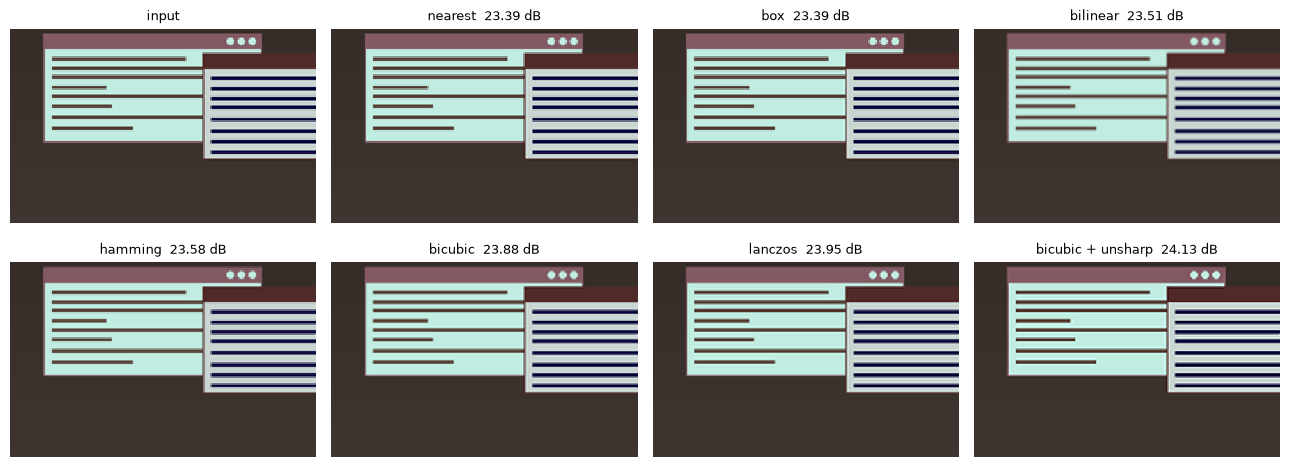

In [5]:
"""One crop through every filter."""

detail = small.crop((0, 0, min(220, small.width), min(140, small.height)))
panels = [("input", detail.resize((detail.width * SCALE, detail.height * SCALE), Image.NEAREST))]
panels += [(f"{m}  {frame_quality[m]:.2f} dB", upscale(detail, m)) for m in METHODS]

fig, axes = plt.subplots(2, 4, figsize=(13, 5))
for ax, (name, image) in zip(axes.ravel(), panels):
    ax.imshow(image, interpolation="nearest")
    ax.set_title(name, fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

## Speed

Two ways to run a filter:

- **PIL**: one image at a time on the CPU;
- **torch** `F.interpolate`: the same call a neural network makes, on the GPU if there is
  one. This is the number to compare a model against.

A batch of one is what matters for a live stream: each frame is needed right away.

In [6]:
"""PIL, one frame at a time."""

rng = np.random.default_rng(SEED)
pil_ms = {}
for size in BENCH_RESOLUTIONS:
    image = Image.fromarray(rng.integers(0, 255, (size[1], size[0], 3), dtype=np.uint8))
    pil_ms[size] = {m: speed.time_ms(lambda m=m: upscale(image, m)) for m in METHODS}

print(f"{'output':>12}" + "".join(f"{m.replace('bicubic + unsharp', 'unsharp'):>10}" for m in METHODS))
for size, row in pil_ms.items():
    out = f"{size[0] * SCALE}x{size[1] * SCALE}"
    print(f"{out:>12}" + "".join(f"{row[m]:10.2f}" for m in METHODS))
print("ms per frame")

      output   nearest       box  bilinear   hamming   bicubic   lanczos   unsharp
     960x540      0.19      1.69      2.25      2.30      3.26      4.40     14.28
    1280x720      0.36      2.99      4.09      3.96      5.85      7.79     24.93
   1920x1080      0.85      6.81      8.82      9.10     13.60     18.29     64.55
   2560x1440      1.66     11.85     15.71     15.65     23.77     31.89    114.88
ms per frame


In [7]:
"""torch F.interpolate, one frame at a time."""

TORCH_MODES = ["nearest", "bilinear", "bicubic"]
torch_filters = {mode: models.Resize(SCALE, mode).to(DEVICE) for mode in TORCH_MODES}

torch_ms = {}
for size in BENCH_RESOLUTIONS:
    x = torch.rand(1, 3, size[1], size[0], device=DEVICE)
    torch_ms[size] = {mode: speed.time_ms(lambda f=f: f(x)) for mode, f in torch_filters.items()}

print(f"{'output':>12}" + "".join(f"{mode:>10}" for mode in TORCH_MODES) + "   fits")
for size, row in torch_ms.items():
    out = f"{size[0] * SCALE}x{size[1] * SCALE}"
    print(f"{out:>12}" + "".join(f"{row[mode]:10.2f}" for mode in TORCH_MODES)
          + f"   {speed.frame_budget(max(row.values()))}")
print("ms per frame")

      output   nearest  bilinear   bicubic   fits
     960x540      0.02      0.02      0.23   60 fps
    1280x720      0.02      0.03      0.40   60 fps
   1920x1080      0.05      0.07      0.86   60 fps
   2560x1440      0.08      0.12      1.51   60 fps
ms per frame


batch     nearest    bilinear     bicubic
    1       0.011       0.012       0.104
    2       0.007       0.008       0.075
    4       0.006       0.007       0.063
    8       0.005       0.006       0.057
   16       0.005       0.006       0.055
ms per frame


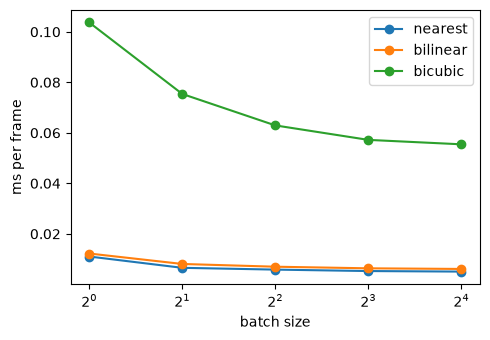

In [ ]:
"""What a bigger batch buys, at 320x180 -> 640x360."""

sweep = {}
for mode, f in torch_filters.items():
    sweep[mode] = {}
    for batch in BENCH_BATCHES:
        x = torch.rand(batch, 3, BENCH_LR_SIZE[1], BENCH_LR_SIZE[0], device=DEVICE)
        sweep[mode][batch] = speed.time_ms(lambda f=f, x=x: f(x)) / batch

print(f"{'batch':>5}" + "".join(f"{mode:>12}" for mode in TORCH_MODES))
for batch in BENCH_BATCHES:
    print(f"{batch:5}" + "".join(f"{sweep[m][batch]:12.3f}" for m in TORCH_MODES))
print("ms per frame")

plt.figure(figsize=(5, 3.5))
for mode in TORCH_MODES:
    plt.plot(BENCH_BATCHES, [sweep[mode][b] for b in BENCH_BATCHES], "o-", label=mode)
plt.xscale("log", base=2)
plt.xlabel("batch size")
plt.ylabel("ms per frame")
plt.legend()
plt.tight_layout()
plt.show()W

## The bar to beat

In [9]:
reference = BENCH_RESOLUTIONS[1]
print(f"quality: {best} at {quality[best]:.2f} dB (bicubic {quality['bicubic']:.2f}, nearest {quality['nearest']:.2f})")
print(f"speed:   bicubic at {reference[0] * SCALE}x{reference[1] * SCALE} costs "
      f"{torch_ms[reference]['bicubic']:.2f} ms (torch), {pil_ms[reference]['bicubic']:.2f} ms (PIL)")

quality: bicubic + unsharp at 35.30 dB (bicubic 34.98, nearest 33.14)
speed:   bicubic at 1280x720 costs 0.40 ms (torch), 5.85 ms (PIL)


## Export to ONNX for the browser

To compare filters and models fairly, both must run in the browser, through the same
runtime. A filter has no weights, so its graph is a single `Resize` node. ONNX `Resize`
only has nearest, linear and cubic, so box, hamming, Lanczos and unsharp cannot be
exported.

The **halo** of a filter is how far it reaches: nearest 0, bilinear 1, bicubic 2.

Note: onnxruntime's CPU `Resize` in cubic mode is very slow (much slower than torch).
That is one slow kernel, not bicubic itself - see `summary.md`.

In [10]:
"""Export the three filters and time them on the desktop CPU."""

EXPORTABLE = {"nearest": 0, "bilinear": 1, "bicubic": 2}   # filter -> halo

for name, halo in EXPORTABLE.items():
    size = webexport.TILE_STEP + 2 * halo
    module = models.Resize(SCALE, name)
    info = webexport.export(module, f"upscale_static_{name}_tile{webexport.TILE_STEP}.onnx", size,
                            label=f"static {name} (Resize)", halo=halo)
    webexport.check_graph(info["path"], module, np.random.rand(1, 3, size, size).astype(np.float32))
    ms = webexport.time_graph(info["path"], size)
    webexport.annotate(info, cpu_ms=round(ms, 2))
    print(webexport.summary_line(info, ms))

print(f"\nwritten to {webexport.MODELS_DIR}")
print("to compare them in a browser: uv run src/upscale/benchmark/main.py")

upscale_static_nearest_tile128.onnx                     0.4 KB    0.02 ms   Constantx1, Resizex1   OUTSIDE BUDGET: Resize
upscale_static_bilinear_tile128.onnx                    0.4 KB    0.12 ms   Constantx1, Resizex1   OUTSIDE BUDGET: Resize
upscale_static_bicubic_tile128.onnx                     0.4 KB   11.49 ms   Constantx1, Resizex1   OUTSIDE BUDGET: Resize

written to /home/henrik/desktop-streamer-ai/dist/upscale
to compare them in a browser: uv run src/upscale/benchmark/main.py
